# 1. Persiapan Lingkungan dan Import Pustaka
Tahap awal dalam alur kerja sistem adalah mempersiapkan pustaka (*libraries*) yang dibutuhkan untuk pemrosesan gambar, augmentasi, pelatihan model Deep Learning, serta evaluasi metrik kinerja akademik.

In [1]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import splitfolders
import albumentations as A

# Konfigurasi optimasi alokasi memori GPU (opsional)
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU siap digunakan dengan alokasi memori dinamis.")
    except RuntimeError as e:
        print(e)
else:
    print("Pelatihan akan menggunakan komputasi CPU.")

Pelatihan akan menggunakan komputasi CPU.


# 2. Partisi Dataset & Distribusi Data
Membaca dataset utama dari folder `dataset` lalu menampilkannya dalam bentuk grafik distribusi visual untuk memastikan data seimbang. Kemudian dataset akan dipecah secara proporsional menjadi **Latih (70%)**, **Validasi (15%)**, dan **Uji (15%)** ke dalam folder `dataset_split`.

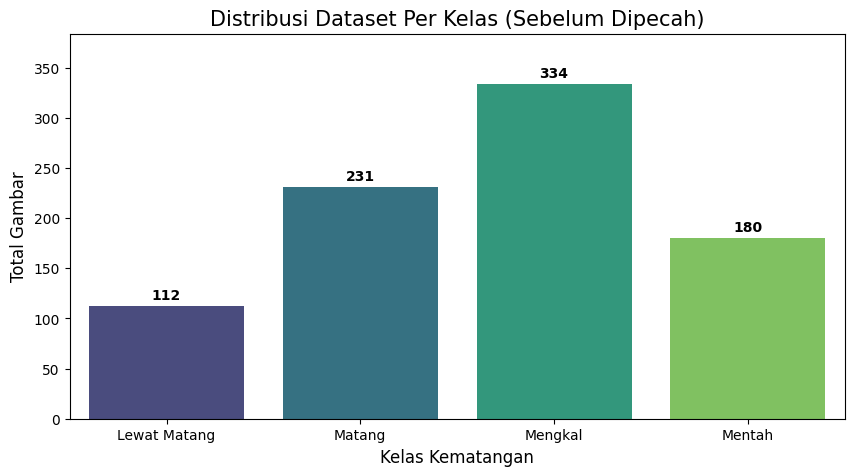


=> Direktori 'dataset_split' sudah ada. Proses split dilewati.


In [2]:
input_dir = 'dataset'
output_dir = 'dataset_split'

# 1. Visualisasi Distribusi Kelas Awal
if os.path.exists(input_dir):
    classes_raw = sorted(os.listdir(input_dir))
    counts = [len(os.listdir(os.path.join(input_dir, c))) for c in classes_raw if os.path.isdir(os.path.join(input_dir, c))]
    
    plt.figure(figsize=(10, 5))
    sns.barplot(x=classes_raw, y=counts, hue=classes_raw, palette='viridis', legend=False)
    plt.title('Distribusi Dataset Per Kelas (Sebelum Dipecah)', fontsize=15)
    plt.xlabel('Kelas Kematangan', fontsize=12)
    plt.ylabel('Total Gambar', fontsize=12)
    for i, v in enumerate(counts):
        plt.text(i, v + (max(counts)*0.02), str(v), ha='center', fontweight='bold')
    plt.ylim(0, max(counts) * 1.15)
    plt.show()

# 2. Pemisahan Dataset (Data Splitting)
if not os.path.exists(output_dir):
    if os.path.exists(input_dir) and len(os.listdir(input_dir)) > 0:
        print("\n=> Memulai pemisahan (splitting) dataset menjadi Latih(70%), Validasi(15%), Uji(15%)...")
        splitfolders.ratio(input_dir, output=output_dir, seed=42, ratio=(0.7, 0.15, 0.15))
        print("\nDataset berhasil dipartisi ke dalam folder 'dataset_split'.")
    else:
        print(f"PERINGATAN: Folder '{input_dir}' kosong atau tidak ditemukan.")
else:
    print("\n=> Direktori 'dataset_split' sudah ada. Proses split dilewati.")

# 3. Pra-pemrosesan & Augmentasi Data (Albumentations)
Penerapan augmentasi pada data latih menggunakan pustaka `Albumentations` meliputi:
- **Resize**: Menjadi 224 x 224.
- **Rotasi & Flip**: Pemantulan dan perputaran acak (±30°).
- **Warna**: Variasi kecerahan dan kontras (0.6 hingga 1.4).
- **Geometrik & Noise**: Zoom ±20% dan suntikan Gaussian Noise untuk memperkuat kekokohan model (Robustness).

In [3]:
# Transformasi Albumentations untuk Data Latih
train_transform = A.Compose([
    A.Resize(224, 224),
    A.Rotate(limit=30, p=0.5),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0, p=0.5), # 1.0 ± 0.4 (0.6 - 1.4)
    A.Affine(scale=(0.8, 1.2), p=0.5), # Zoom ±20%
    A.GaussNoise(var_limit=(10.0, 50.0), p=0.5),
    A.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5), max_pixel_value=255.0) # Normalisasi 0-1
])

# Transformasi Data Validasi dan Uji (Tanpa Augmentasi Buatan)
val_test_transform = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5), max_pixel_value=255.0)
])

# Generator Data Kustom berbasis tf.keras.utils.Sequence
class SawitDataGenerator(tf.keras.utils.Sequence):
    def __init__(self, image_paths, labels, batch_size, transform, classes):
        self.image_paths = image_paths
        self.labels = labels
        self.batch_size = batch_size
        self.transform = transform
        self.classes = classes
        self.num_classes = len(classes)
        
    def __len__(self):
        return int(np.ceil(len(self.image_paths) / float(self.batch_size)))
    
    def __getitem__(self, idx):
        batch_paths = self.image_paths[idx * self.batch_size:(idx + 1) * self.batch_size]
        batch_labels = self.labels[idx * self.batch_size:(idx + 1) * self.batch_size]
        
        images, labels_encoded = [], []
        for path, label in zip(batch_paths, batch_labels):
            img = cv2.imread(path)
            if img is None: continue
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            
            if self.transform:
                augmented = self.transform(image=img)
                img = augmented['image']
                
            images.append(img)
            labels_encoded.append(self.classes.index(label))
            
        return np.array(images), tf.keras.utils.to_categorical(labels_encoded, num_classes=self.num_classes)

def get_dataset_metadata(folder_path):
    paths, labels = [], []
    try:
        classes = sorted(os.listdir(folder_path))
    except FileNotFoundError:
        return [], [], []
    for cls in classes:
        cls_dir = os.path.join(folder_path, cls)
        if os.path.isdir(cls_dir):
            for img in os.listdir(cls_dir):
                paths.append(os.path.join(cls_dir, img))
                labels.append(cls)
    return paths, labels, classes

# Memuat Dataset
train_paths, train_labels, classes = get_dataset_metadata('dataset_split/train')
val_paths, val_labels, _ = get_dataset_metadata('dataset_split/val')
test_paths, test_labels, _ = get_dataset_metadata('dataset_split/test')

BATCH_SIZE = 32
if classes:
    train_gen = SawitDataGenerator(train_paths, train_labels, BATCH_SIZE, train_transform, classes)
    val_gen = SawitDataGenerator(val_paths, val_labels, BATCH_SIZE, val_test_transform, classes)
    test_gen = SawitDataGenerator(test_paths, test_labels, BATCH_SIZE, val_test_transform, classes)
    print(f"Total Data - Latih: {len(train_paths)} | Validasi: {len(val_paths)} | Uji: {len(test_paths)}")
else:
    print("Folder dataset_split belum siap.")

Total Data - Latih: 597 | Validasi: 127 | Uji: 133


C:\Users\peno\AppData\Local\Temp\ipykernel_22460\3929492058.py:8: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 50.0), p=0.5),


# 4. Visualisasi Hasil Augmentasi Data Latih
Membuktikan secara visual bahwa augmentasi `Albumentations` bekerja memodifikasi gambar-gambar di dalam *batch* memori sebelum diberikan kepada model neural.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.882353..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.82745105..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RG

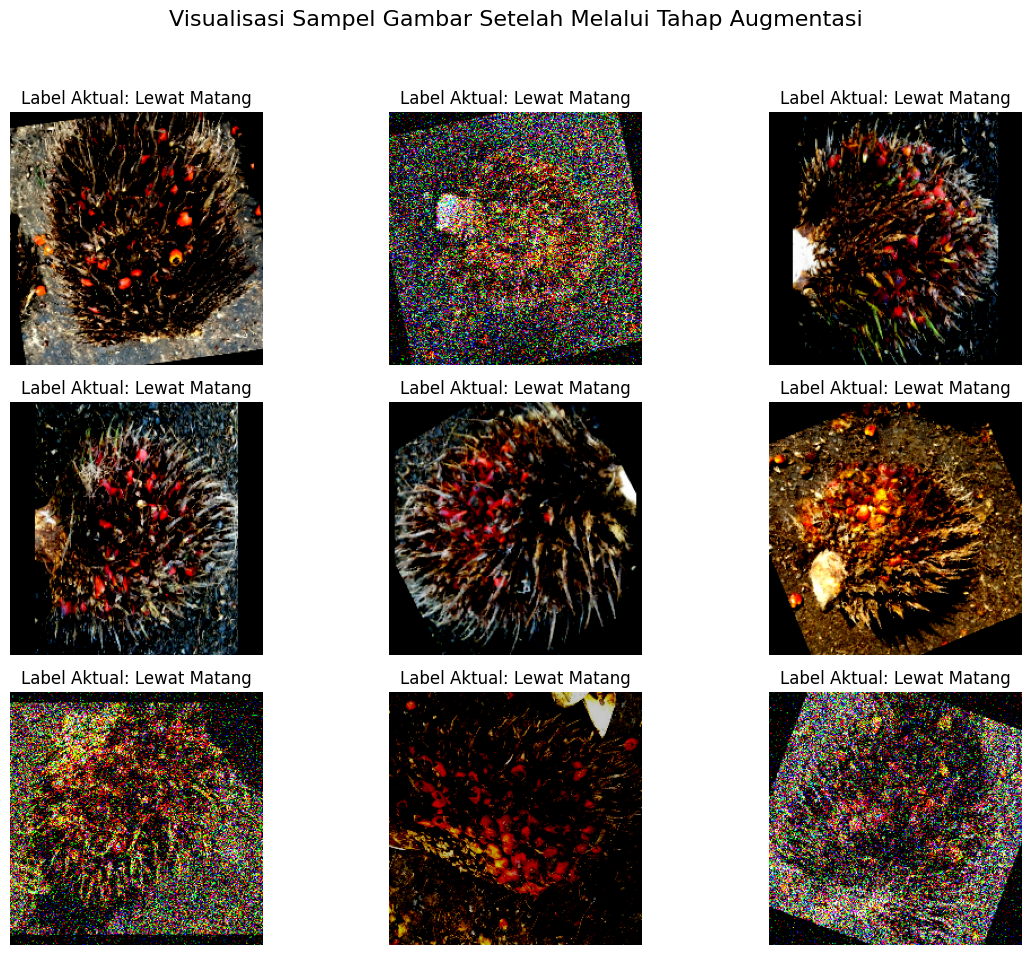

In [4]:
if classes and len(train_gen) > 0:
    # Mengambil sampel 1 batch data latih
    sample_images, sample_labels = train_gen[0]
    
    plt.figure(figsize=(12, 10))
    for i in range(min(9, len(sample_images))):
        plt.subplot(3, 3, i + 1)
        # Gambar sudah dinormalisasi (0-1), imshow dapat merender float 0-1 dengan baik
        plt.imshow(sample_images[i])
        label_name = classes[np.argmax(sample_labels[i])]
        plt.title(f"Label Aktual: {label_name}", fontsize=12)
        plt.axis('off')
        
    plt.suptitle("Visualisasi Sampel Gambar Setelah Melalui Tahap Augmentasi", fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()
else:
    print("Gagal menampilkan augmentasi: Dataset latih kosong.")

# 5. Arsitektur Model: Transfer Learning (Tahap Ekstraksi Fitur)
Pembuatan model dasar menggunakan arsitektur **MobileNetV2**. 
- **Fase Frozen (15 Epochs)**: Bobot pratelatih ImageNet dikunci (*frozen*). Algoritma hanya memperbarui *Classifier Layers* (lapisan klasifikasi khusus 4 kelas sawit).
- **Learning Rate**: 0.001.

In [5]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

if classes:
    # Load MobileNetV2
    base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False # Membekukan ekstraktor fitur

    # Tambahkan lapisan kustom di atas model dasar
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    predictions = Dense(len(classes), activation='softmax')(x)
    model = Model(inputs=base_model.input, outputs=predictions)

    # Kompilasi Model Tahap 1
    model.compile(optimizer=Adam(learning_rate=0.001), 
                  loss='categorical_crossentropy', 
                  metrics=['accuracy'])

    print("--- Memulai Eksekusi Pelatihan Tahap 1 (Frozen Base) ---")
    # AKTIFKAN pelatihan model dengan menghapus tanda komentar di bawah ini
    from sklearn.utils.class_weight import compute_class_weight
    
    # Kalkulasi pembobotan kelas untuk mengatasi dataset tidak seimbang
    class_weights_arr = compute_class_weight(class_weight='balanced', classes=np.unique(train_labels), y=train_labels)
    class_weight_dict = {i: weight for i, weight in enumerate(class_weights_arr)}
    print(f"\nDistribusi Class Weights: {class_weight_dict}")
    
    history_phase1 = model.fit(train_gen, validation_data=val_gen, epochs=15, class_weight=class_weight_dict)
else:
    print("Model dibatalkan karena dataset belum siap.")

--- Memulai Eksekusi Pelatihan Tahap 1 (Frozen Base) ---

Distribusi Class Weights: {0: np.float64(1.9134615384615385), 1: np.float64(0.9270186335403726), 2: np.float64(0.6405579399141631), 3: np.float64(1.194)}


c:\Users\peno\anaconda3\envs\sawit_env\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 92s 4s/step - accuracy: 0.2680 - loss: 2.4853 - val_accuracy: 0.2992 - val_loss: 1.7125
Epoch 2/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 51s 3s/step - accuracy: 0.1374 - loss: 1.8924 - val_accuracy: 0.2992 - val_loss: 1.3806
Epoch 3/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 73s 2s/step - accuracy: 0.3199 - loss: 1.4677 - val_accuracy: 0.3858 - val_loss: 1.3119
Epoch 4/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.3183 - loss: 1.4313 - val_accuracy: 0.4567 - val_loss: 1.1429
Epoch 5/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step - accuracy: 0.4087 - loss: 1.3649 - val_accuracy: 0.4882 - val_loss: 1.2093
Epoch 6/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step - accuracy: 0.3735 - loss: 1.2667 - val_accuracy: 0.5197 - val_loss: 1.0748
Epoch 7/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 80s 2s/step - accuracy: 0.3601 - loss: 1.3552 - val_accuracy: 0.4882 - val_loss: 1.1730
Epoch 8/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.3819 - loss: 1.1647 - val_accuracy: 0.5433 - val_loss:

# 6. Transfer Learning (Tahap Penyesuaian Halus / Fine-Tuning)
Meningkatkan akurasi deteksi pola mikroskopik spesifik dari fisik Tandan Buah Segar dengan membuka (*unfreeze*) 30 layer konvolusi teratas.
- **Fase Unfrozen (30 Epochs)**: Agar *Catastrophic Forgetting* tidak terjadi, *Learning Rate* direduksi sangat kecil secara radikal (0.00001).

In [6]:
if classes:
    base_model.trainable = True

    # Bekukan semua kecuali 30 layer terakhir
    for layer in base_model.layers[:-30]:
        layer.trainable = False

    # Kompilasi Ulang dengan LR super lambat
    model.compile(optimizer=Adam(learning_rate=0.00001), 
                  loss='categorical_crossentropy', 
                  metrics=['accuracy'])

    print("\n--- Memulai Eksekusi Pelatihan Tahap 2 (Fine-Tuning) ---")
    # AKTIFKAN pelatihan model dengan menghapus tanda komentar di bawah ini
    history_phase2 = model.fit(train_gen, validation_data=val_gen, epochs=30, class_weight=class_weight_dict)
else:
    print("Tahap 2 dilewati.")


--- Memulai Eksekusi Pelatihan Tahap 2 (Fine-Tuning) ---
Epoch 1/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 82s 3s/step - accuracy: 0.3920 - loss: 1.9354 - val_accuracy: 0.6220 - val_loss: 0.8422
Epoch 2/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 65s 2s/step - accuracy: 0.3836 - loss: 1.7748 - val_accuracy: 0.5984 - val_loss: 0.8719
Epoch 3/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step - accuracy: 0.3735 - loss: 1.7280 - val_accuracy: 0.5512 - val_loss: 0.9284
Epoch 4/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 52s 3s/step - accuracy: 0.3735 - loss: 1.6174 - val_accuracy: 0.5276 - val_loss: 0.9928
Epoch 5/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.3853 - loss: 1.5794 - val_accuracy: 0.5118 - val_loss: 1.0352
Epoch 6/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.3551 - loss: 1.5345 - val_accuracy: 0.5118 - val_loss: 1.0878
Epoch 7/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - accuracy: 0.2998 - loss: 1.5113 - val_accuracy: 0.4961 - val_loss: 1.1355
Epoch 8/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy

# 7. Kuantisasi ke Ekosistem Android Mobile (TensorFlow Lite)
Optimalisasi dan sintesis model ke arsitektur `TFLite` dengan kompresi tipe bilangan Float16, dirancang secara khusus guna memenuhi batasan latensi dan spesifikasi memori rendah pada platform Android (~7 MB).

In [7]:
if classes and 'history_phase2' in locals():
    print("Mengeksekusi Post-Training Quantization (Float16)...")
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.target_spec.supported_types = [tf.float16]

    tflite_quant_model = converter.convert()
    
    tflite_filepath = "mobilenetv2_sawit_fp16.tflite"
    with open(tflite_filepath, "wb") as f:
        f.write(tflite_quant_model)
    
    size_mb = os.path.getsize(tflite_filepath) / (1024 * 1024)
    print(f"\u2714 Sintesis Model TFLite Berhasil Disimpan: {tflite_filepath}")
    print(f"\u2714 Ukuran File Terkompresi: {size_mb:.2f} MB")
else:
    print("Model belum selesai dilatih, konversi TFLite ditunda.")

Mengeksekusi Post-Training Quantization (Float16)...
INFO:tensorflow:Assets written to: C:\Users\peno\AppData\Local\Temp\tmpugssuj81\assets


INFO:tensorflow:Assets written to: C:\Users\peno\AppData\Local\Temp\tmpugssuj81\assets


Saved artifact at 'C:\Users\peno\AppData\Local\Temp\tmpugssuj81'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  2418568079392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2418629667024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2418629666144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2418629664912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2418629666496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2418219418720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2418630067296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2418629672656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2418629671952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2418630066240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  241863

# 8. Evaluasi Akademik 1: Visualisasi Kurva Konvergensi
Memetakan rekaman pergerakan metrik *Accuracy* dan *Loss Function* terhadap dimensi temporal (Epoch) guna mengobservasi perilaku model saat tahap sinkronisasi awal, dan efek pasca transisi ke fase *fine-tuning*.

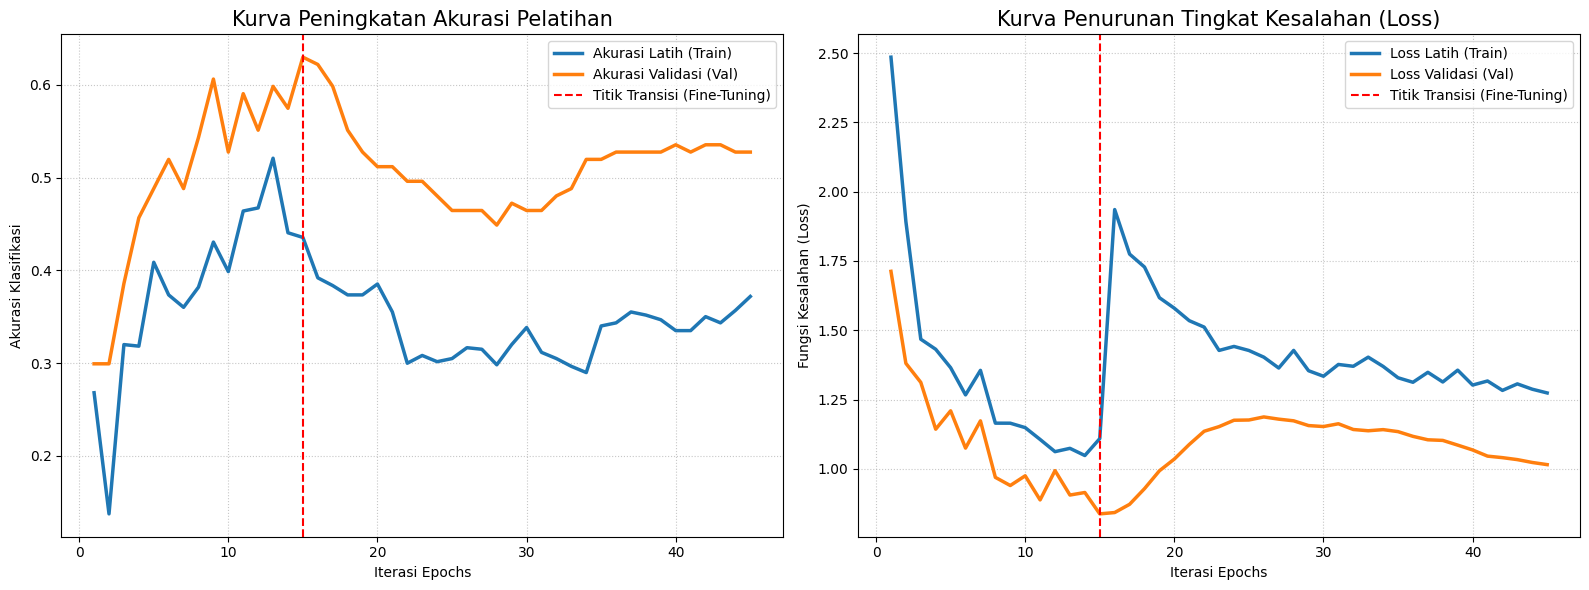

In [8]:
if 'history_phase1' in locals() and 'history_phase2' in locals():
    # Penggabungan log history
    acc = history_phase1.history['accuracy'] + history_phase2.history['accuracy']
    val_acc = history_phase1.history['val_accuracy'] + history_phase2.history['val_accuracy']
    loss = history_phase1.history['loss'] + history_phase2.history['loss']
    val_loss = history_phase1.history['val_loss'] + history_phase2.history['val_loss']
    
    epochs_axis = range(1, len(acc) + 1)
    
    plt.figure(figsize=(16, 6))
    
    # Kurva Metrik Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(epochs_axis, acc, label='Akurasi Latih (Train)', linewidth=2.5)
    plt.plot(epochs_axis, val_acc, label='Akurasi Validasi (Val)', linewidth=2.5)
    plt.axvline(x=15, color='red', linestyle='--', label='Titik Transisi (Fine-Tuning)')
    plt.title('Kurva Peningkatan Akurasi Pelatihan', fontsize=15)
    plt.xlabel('Iterasi Epochs')
    plt.ylabel('Akurasi Klasifikasi')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)
    
    # Kurva Metrik Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_axis, loss, label='Loss Latih (Train)', linewidth=2.5)
    plt.plot(epochs_axis, val_loss, label='Loss Validasi (Val)', linewidth=2.5)
    plt.axvline(x=15, color='red', linestyle='--', label='Titik Transisi (Fine-Tuning)')
    plt.title('Kurva Penurunan Tingkat Kesalahan (Loss)', fontsize=15)
    plt.xlabel('Iterasi Epochs')
    plt.ylabel('Fungsi Kesalahan (Loss)')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)
    
    plt.tight_layout()
    plt.show()
else:
    print("Kurva tidak bisa di-render: Pelatihan belum selesai dijalankan.")

# 9. Evaluasi Akademik 2: Confusion Matrix & Verifikasi Target Kinerja
Prosedur eksklusif uji akhir (*testing phase*) menggunakan dataset unseen 15% untuk mengkalkulasi Confusion Matrix 4x4, Metrik Performa, dan mencocokkan hasil eksperimen terhadap ambang batas minimal yang ditetapkan dalam PRD (Product Requirements Document).
- Syarat Minimal Akurasi Total: **88.00%**
- Syarat Minimal Recall Kelas 'Matang': **90.00%**

Memulai inferensi diagnostik pada Dataset Uji (Testing Data)...


c:\Users\peno\anaconda3\envs\sawit_env\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


5/5 ━━━━━━━━━━━━━━━━━━━━ 30s 3s/step


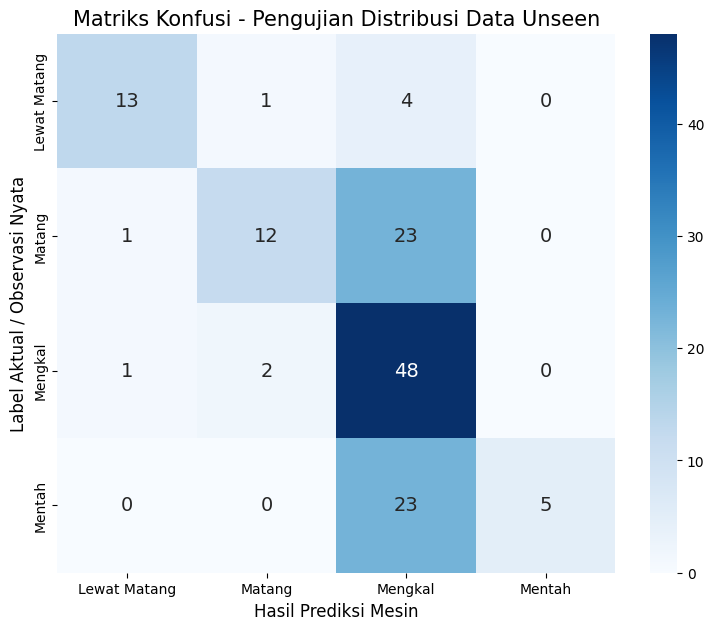


LAPORAN LENGKAP METRIK KINERJA (CLASSIFICATION REPORT)
              precision    recall  f1-score   support

Lewat Matang       0.87      0.72      0.79        18
      Matang       0.80      0.33      0.47        36
     Mengkal       0.49      0.94      0.64        51
      Mentah       1.00      0.18      0.30        28

    accuracy                           0.59       133
   macro avg       0.79      0.54      0.55       133
weighted avg       0.73      0.59      0.54       133


HASIL VALIDASI TARGET (PRD OBJECTIVES)
[+] Kalkulasi Akurasi Keseluruhan Sistem : 58.65% 	| Target >= 88.00%
[+] Sensitivitas (Recall) Kelas 'Matang': 33.33% 	| Target >= 90.00%

✖ STATUS: BELUM MEMENUHI STANDAR (Dibutuhkan iterasi eksperimen). ✖


In [9]:
if 'model' in locals() and classes:
    print("Memulai inferensi diagnostik pada Dataset Uji (Testing Data)...")
    y_pred_probs = model.predict(test_gen)
    y_pred = np.argmax(y_pred_probs, axis=1)
    
    # Vektor Kebenaran Aktual (Ground Truth)
    y_true = []
    for i in range(len(test_gen)):
        _, batch_y = test_gen[i]
        y_true.extend(np.argmax(batch_y, axis=1))
    y_true = np.array(y_true)
    
    # Matriks Konfusi Visual
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=classes, yticklabels=classes, annot_kws={"size": 14})
    plt.title('Matriks Konfusi - Pengujian Distribusi Data Unseen', fontsize=15)
    plt.ylabel('Label Aktual / Observasi Nyata', fontsize=12)
    plt.xlabel('Hasil Prediksi Mesin', fontsize=12)
    plt.show()
    
    # Ekstraksi Laporan Metrik Statis
    print("\n=======================================================================")
    print("LAPORAN LENGKAP METRIK KINERJA (CLASSIFICATION REPORT)")
    print("=======================================================================")
    print(classification_report(y_true, y_pred, target_names=classes))
    
    # Validasi Matematis terhadap Ambang Batas Target Sistem
    try:
        idx_matang = classes.index('Matang')
        recall_matang = cm[idx_matang, idx_matang] / np.sum(cm[idx_matang, :])
        akurasi_total = np.trace(cm) / np.sum(cm)
        
        print("\n=======================================================================")
        print("HASIL VALIDASI TARGET (PRD OBJECTIVES)")
        print("=======================================================================")
        print(f"[+] Kalkulasi Akurasi Keseluruhan Sistem : {akurasi_total:.2%} \t| Target >= 88.00%")
        print(f"[+] Sensitivitas (Recall) Kelas 'Matang': {recall_matang:.2%} \t| Target >= 90.00%")
        print("=======================================================================")
        if akurasi_total >= 0.88 and recall_matang >= 0.90:
            print("\n\u2714 STATUS: LULUS UJI (Model memenuhi standar kelayakan operasi). \u2714")
        else:
            print("\n\u2716 STATUS: BELUM MEMENUHI STANDAR (Dibutuhkan iterasi eksperimen). \u2716")
    except ValueError:
        print("Peringatan: Variabel target 'Matang' tidak ada di dalam kelas terdeteksi.")
else:
    print("Pengujian tidak dapat dilakukan sebelum model selesai dilatih.")